# Local Cursor PyTorch workbook

This is the complete local workflow: create or sync the project, open it in Cursor, start the folder-local kernel, run PyTorch, and stop the kernel.

## Before opening Cursor

Run this in a terminal on the Mac:

```bash
cd ~/Developer/cursor-notebook-workspace
uv sync
uv run pytest
```

`uv sync` creates or reconciles `./.venv` from `pyproject.toml` and `uv.lock`. It does not start a kernel.

## Start the local kernel in Cursor

1. Open the project with `cursor -r .`.
2. Open this notebook from the Explorer.
3. In the notebook toolbar, click `Select Kernel` (or the current kernel name).
4. Choose `Select Another Kernel...`.
5. Choose `Python Environments...`, then choose the workspace `.venv/bin/python`.
6. Click `Run All`. Running the first code cell starts the kernel process on demand.

## Keyboard controls on macOS

- Execute the selected cell: `Control+Enter` (`⌃⏎`).
- Add a code cell: `Command+Enter` (`⌘⏎`). This does not execute the current cell.
- Execute everything: click `Run All` in the notebook toolbar.

Do not use the Command Palette's `Jupyter: Manage Access To Jupyter Kernels`; that manages extension access and does not select this notebook's kernel.

![Cursor notebook kernel picker flow](../docs/images/cursor-kernel-picker-flow.svg)

The kernel is a Python process. The `.venv/bin/python` interpreter and its Jupyter support live inside this project folder.

## What success looks like

The first cell prints `sys.executable` inside `.venv`, the Python and PyTorch versions, and `mps` or `cpu` as the device on the Mac. The remaining cells test matrix multiplication, autograd, and inline plotting.

## Stop or reset

Use the notebook `Restart` control to replace the running process and reset its state. Close Cursor or explicitly shut down the kernel when finished. The notebook file and saved outputs remain; Python variables in memory do not.

In [14]:
import platform
import sys

import torch

# This code runs inside the Python kernel selected in Cursor.
# The project-local .venv keeps its packages separate from global Python.
assert ".venv" in sys.executable, f"Expected the project .venv, got {sys.executable}"
# On this Mac, prefer Apple's local GPU; otherwise use CPU.
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(
    {
        "python": sys.version.split()[0],
        "executable": sys.executable,
        "platform": platform.platform(),
        "torch": torch.__version__,
        "device": str(device),
    }
)

{'python': '3.12.12', 'executable': '/Users/andrewho/Developer/cursor-notebook-workspace/.venv/bin/python', 'platform': 'macOS-26.6.2-arm64-arm-64bit', 'torch': '2.11.0', 'device': 'mps'}


In [15]:
left = torch.ones((32, 32), device=device)
right = torch.full((32, 32), 2.0, device=device)
product = left @ right
print(
    {"device": str(product.device), "shape": tuple(product.shape), "sample": float(product[0, 0])}
)

{'device': 'mps:0', 'shape': (32, 32), 'sample': 64.0}


In [37]:
weights = torch.randn(32, 32, device=device, requires_grad=True)
loss = weights.square().mean()
loss.backward()
print(
    {"loss": loss.detach().cpu().item(), "gradient_norm": weights.grad.norm().detach().cpu().item()}
)

{'loss': 1.0403187274932861, 'gradient_norm': 0.06374751031398773}


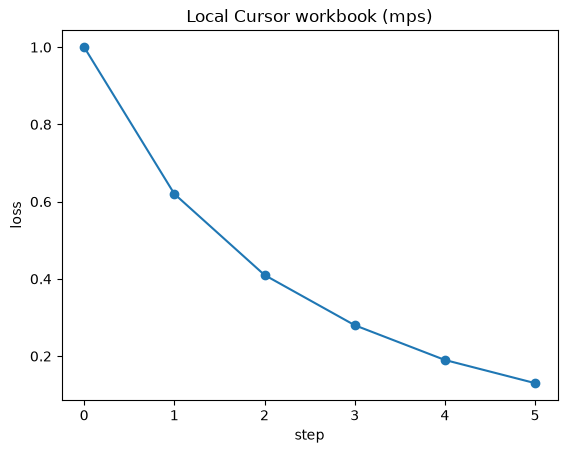

In [40]:
import matplotlib.pyplot as plt

losses = [1.0, 0.62, 0.41, 0.28, 0.19, 0.13]
plt.plot(losses, marker="o")
plt.title(f"Local Cursor workbook ({device})")
plt.xlabel("step")
plt.ylabel("loss")
plt.show()